# 02B — ByteTrack smoke test (isolated, one video)

This notebook tests the **specific `YOLO.track(..., tracker='bytetrack.yaml')` call** that has not yet been checked by the environment diagnostic.

- Uses the existing Anaconda Python kernel; no installation or package changes.
- Runs ByteTrack in a separate worker process so a native crash should not terminate Jupyter.
- Reads one existing video from the original manifest and processes at most 60 frames on CPU.
- Writes only to `Notebook_2_Improved_v2/logs/bytetrack_smoke_v1/` and `outputs/bytetrack_smoke_v1/`.
- Does not run ViTPose, change NPZ files, or touch previous models.

Do not proceed to full tracking until this smoke test returns code 0 and shows stable IDs in the preview.

In [1]:
from pathlib import Path
import sys, json, subprocess, textwrap, os
import pandas as pd

PROJECT_DIR = Path(r"C:\Users\admin\ViTPose_Action_Recognition")
NOTEBOOK2_DIR = PROJECT_DIR / "Notebook_2_Improved_v2"
MANIFEST_PATH = PROJECT_DIR / "data" / "processed" / "manifest.csv"
WEIGHT_CANDIDATES = [PROJECT_DIR / "notebooks" / "yolo11n.pt",
                     PROJECT_DIR / "yolo11n.pt"]
YOLO_WEIGHTS = next((p for p in WEIGHT_CANDIDATES if p.is_file()), None)
LOG_DIR = NOTEBOOK2_DIR / "logs" / "bytetrack_smoke_v1"
OUT_DIR = NOTEBOOK2_DIR / "outputs" / "bytetrack_smoke_v1"
LOG_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

MAX_FRAMES = 60
IMGSZ = 320
CONF = 0.15
DEVICE = "cpu"
TRACKER = "bytetrack.yaml"

assert MANIFEST_PATH.is_file(), f"Manifest not found: {MANIFEST_PATH}"
assert YOLO_WEIGHTS is not None, "YOLO weights not found in expected project locations."
manifest = pd.read_csv(MANIFEST_PATH)
required = {"video_path", "label"}
missing = required - set(manifest.columns)
assert not missing, f"Manifest missing columns: {missing}"

# Prefer a Typing sample; otherwise use the first valid video in the manifest.
candidates = manifest[manifest["label"].astype(str).str.casefold() == "typing"]
if candidates.empty:
    candidates = manifest
chosen = None
for _, row in candidates.iterrows():
    candidate = Path(str(row["video_path"]))
    if candidate.is_file():
        chosen = row
        break
assert chosen is not None, "No existing video path was found in the manifest."
VIDEO_PATH = Path(str(chosen["video_path"]))
VIDEO_LABEL = str(chosen["label"])

print("Python:", sys.executable)
print("Manifest:", MANIFEST_PATH)
print("YOLO weights:", YOLO_WEIGHTS)
print("Test video:", VIDEO_PATH)
print("Class:", VIDEO_LABEL)
print("Frames limit:", MAX_FRAMES, "| Device:", DEVICE, "| Tracker:", TRACKER)


Python: C:\Users\admin\anaconda3\python.exe
Manifest: C:\Users\admin\ViTPose_Action_Recognition\data\processed\manifest.csv
YOLO weights: C:\Users\admin\ViTPose_Action_Recognition\notebooks\yolo11n.pt
Test video: C:\Users\admin\ViTPose_Action_Recognition\data\raw\ucf_sports\Typing\v_Typing_g01_c01.avi
Class: Typing
Frames limit: 60 | Device: cpu | Tracker: bytetrack.yaml


## Run ByteTrack in a separate process
The worker captures its own stdout/stderr. A worker failure is recorded in its log and return code, while this notebook kernel remains available.

In [2]:
worker_code = r'''
import os, sys, json, time, traceback
from pathlib import Path

# Set conservative thread counts before importing numerical libraries.
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"

video_path = Path(sys.argv[1])
weights = Path(sys.argv[2])
out_dir = Path(sys.argv[3])
result_path = Path(sys.argv[4])
max_frames = int(sys.argv[5])
imgsz = int(sys.argv[6])
conf = float(sys.argv[7])
device = sys.argv[8]
tracker = sys.argv[9]
out_dir.mkdir(parents=True, exist_ok=True)

try:
    print("WORKER_START", flush=True)
    import torch
    torch.set_num_threads(1)
    import cv2
    cv2.setNumThreads(1)
    import numpy as np
    from ultralytics import YOLO
    print("IMPORTS_OK", "torch", torch.__version__, "cv2", cv2.__version__, flush=True)

    model = YOLO(str(weights))
    print("YOLO_LOAD_OK", flush=True)
    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        raise RuntimeError(f"OpenCV cannot open video: {video_path}")

    processed = 0
    frame_with_detection = 0
    ids_seen = set()
    preview_paths = []
    frame_stride = max(1, max_frames // 6)
    started = time.time()

    while processed < max_frames:
        ok, frame = cap.read()
        if not ok:
            break
        result = model.track(
            frame, persist=True, tracker=tracker, classes=[0],
            conf=conf, imgsz=imgsz, device=device, verbose=False
        )[0]
        processed += 1
        boxes = result.boxes
        if boxes is not None and len(boxes) > 0:
            frame_with_detection += 1
            if boxes.id is not None:
                ids = boxes.id.detach().cpu().numpy().astype(int).tolist()
                ids_seen.update(i for i in ids if i >= 0)

        if processed == 1 or processed % frame_stride == 0:
            annotated = result.plot()
            preview = out_dir / f"track_{processed:04d}.jpg"
            if not cv2.imwrite(str(preview), annotated):
                raise RuntimeError(f"Could not save preview: {preview}")
            preview_paths.append(str(preview))

        if processed % 10 == 0:
            print(f"PROGRESS frames={processed} detected_frames={frame_with_detection} ids={len(ids_seen)}", flush=True)

    cap.release()
    summary = {
        "status": "success", "video_path": str(video_path),
        "frames_processed": processed,
        "frames_with_person_detection": frame_with_detection,
        "detection_frame_rate": frame_with_detection / max(processed, 1),
        "unique_track_ids": sorted(ids_seen),
        "unique_track_count": len(ids_seen),
        "preview_paths": preview_paths,
        "elapsed_seconds": round(time.time() - started, 2),
        "device": device, "tracker": tracker
    }
    result_path.write_text(json.dumps(summary, indent=2), encoding="utf-8")
    print("TRACKING_OK", json.dumps(summary), flush=True)
except BaseException as exc:
    try:
        cap.release()
    except Exception:
        pass
    print("WORKER_EXCEPTION", repr(exc), flush=True)
    traceback.print_exc()
    raise
'''

worker_path = LOG_DIR / "bytetrack_worker.py"
worker_path.write_text(textwrap.dedent(worker_code), encoding="utf-8")
stdout_path = LOG_DIR / "worker_stdout.log"
stderr_path = LOG_DIR / "worker_stderr.log"
result_path = OUT_DIR / "tracking_smoke_result.json"

# Do not accidentally reuse a stale result from an earlier attempt.
if result_path.exists():
    result_path.unlink()

cmd = [sys.executable, str(worker_path), str(VIDEO_PATH), str(YOLO_WEIGHTS),
       str(OUT_DIR), str(result_path), str(MAX_FRAMES), str(IMGSZ),
       str(CONF), DEVICE, TRACKER]

print("Launching isolated ByteTrack worker...")
try:
    with stdout_path.open("w", encoding="utf-8", errors="replace") as out, \
         stderr_path.open("w", encoding="utf-8", errors="replace") as err:
        proc = subprocess.run(cmd, stdout=out, stderr=err, timeout=300, check=False)
    return_code = proc.returncode
except subprocess.TimeoutExpired:
    return_code = 124
    print("Worker timed out after 300 seconds.")

print("Worker return code:", return_code)
print("STDOUT log:", stdout_path)
print("STDERR log:", stderr_path)
if return_code == 0 and result_path.is_file():
    result = json.loads(result_path.read_text(encoding="utf-8"))
    print(json.dumps(result, indent=2))
else:
    print("Worker did not complete. Do not increase frames or launch full extraction.")
    print("\n--- STDOUT tail ---")
    print(stdout_path.read_text(encoding="utf-8", errors="replace")[-5000:])
    print("\n--- STDERR tail ---")
    print(stderr_path.read_text(encoding="utf-8", errors="replace")[-5000:])


Launching isolated ByteTrack worker...
Worker return code: 3
STDOUT log: C:\Users\admin\ViTPose_Action_Recognition\Notebook_2_Improved_v2\logs\bytetrack_smoke_v1\worker_stdout.log
STDERR log: C:\Users\admin\ViTPose_Action_Recognition\Notebook_2_Improved_v2\logs\bytetrack_smoke_v1\worker_stderr.log
Worker did not complete. Do not increase frames or launch full extraction.

--- STDOUT tail ---
WORKER_START
IMPORTS_OK torch 2.7.1+cu118 cv2 4.13.0
YOLO_LOAD_OK


--- STDERR tail ---
OMP: Error #15: Initializing libiomp5md.dll, but found libiomp5md.dll already initialized.
OMP: Hint This means that multiple copies of the OpenMP runtime have been linked into the program. That is dangerous, since it can degrade performance or cause incorrect results. The best thing to do is to ensure that only a single OpenMP runtime is linked into the process, e.g. by avoiding static linking of the OpenMP runtime in any library. As an unsafe, unsupported, undocumented workaround you can set the environment va

## Review saved preview images
Run this cell only after the worker finishes. It displays a small set of saved annotated frames.

Preview images: 1


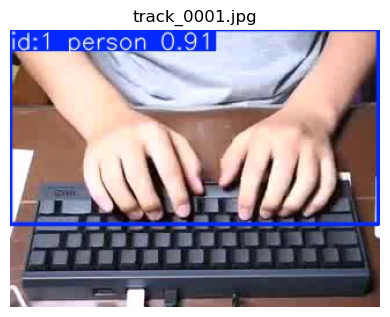

No successful result JSON. Use the worker logs above for diagnosis.


In [3]:
from PIL import Image
import matplotlib.pyplot as plt

preview_files = sorted(OUT_DIR.glob("track_*.jpg"))
print("Preview images:", len(preview_files))
if preview_files:
    fig, axes = plt.subplots(1, len(preview_files), figsize=(4 * len(preview_files), 4))
    if len(preview_files) == 1:
        axes = [axes]
    for ax, path in zip(axes, preview_files):
        with Image.open(path) as im:
            ax.imshow(im.copy())
        ax.set_title(path.name)
        ax.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("No preview images were saved.")

if result_path.is_file():
    result = json.loads(result_path.read_text(encoding="utf-8"))
    print("\nTRACKING SUMMARY")
    for key in ["frames_processed", "frames_with_person_detection", "detection_frame_rate",
                "unique_track_count", "unique_track_ids", "elapsed_seconds"]:
        print(f"{key}: {result.get(key)}")
else:
    print("No successful result JSON. Use the worker logs above for diagnosis.")


## Decision
Proceed to the five-video tracking pilot only if the worker return code is `0`, a result JSON is saved, preview frames show correct person boxes, and track IDs behave reasonably across frames. If the worker fails, send `worker_stdout.log` and `worker_stderr.log`; do not run Notebook 03.